# Topic cluster map: `universal_clean_k50_seed0`

Notebook version of `results/quality/topics/universal_clean_k50_seed0/clusters.html` (`scripts/topics/plot_topic_clusters.py`). Same inputs, cluster-level data only, no tweets: `analysis.json` and `layout.json` from `scripts/topics/analyze_topic_clusters.py`. Names from `configs/quality/topic_names_universal_clean_k50.json` (D-019).

In [1]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

# Run from the repo root whether the notebook is opened from notebooks/ or the root.
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)

D = Path("results/quality/topics/universal_clean_k50_seed0")
A = json.loads((D / "analysis.json").read_text(encoding="utf-8"))
L = json.loads((D / "layout.json").read_text(encoding="utf-8"))
CL = {c["cluster"]: c for c in A["clusters"]}

# Topics whose clusters are mostly reviews (as in plot_topic_clusters.py); the rest are tweets and comments.
REVIEW_TOPICS = {"Books and novels", "Hotels and stays", "Restaurants and food", "Products and shopping",
                 "Places, malls and attractions", "Apps, phones and technology", "Films, TV, music and celebrities"}
COLORS = {"review": "#2a78d6", "tweet": "#eb6834", "unnamed": "#a3a29c"}   # dataviz reference palette


def group(c: int) -> str:
    """Colour group of a cluster: review topic, tweet/comment topic or not named."""
    t = CL[c]["topic"]
    return "unnamed" if t == "Not named" else ("review" if t in REVIEW_TOPICS else "tweet")

## Key findings

In [2]:
ranks = A["nearest_same_topic_rank"]
print(f"Same-topic clusters are closer than different-topic clusters: mean centroid similarity "
      f"{A['same_topic_sim']['mean']:.3f} vs {A['different_topic_sim']['mean']:.3f}.")
print(f"For {sum(r == 1 for r in ranks.values())} of {len(ranks)} clusters in a multi-cluster topic, the nearest cluster overall has the same topic.")
print(f"Centroid similarity correlates with dataset-mix similarity: r = {A['corr_centroid_sim_vs_dataset_mix_sim']:.2f} (closeness follows the source as well as the subject).")

Same-topic clusters are closer than different-topic clusters: mean centroid similarity 0.975 vs 0.950.
For 22 of 35 clusters in a multi-cluster topic, the nearest cluster overall has the same topic.
Centroid similarity correlates with dataset-mix similarity: r = 0.60 (closeness follows the source as well as the subject).


## Map of texts (t-SNE)

`per_cluster` texts per cluster, placed by t-SNE on their E5 embeddings (cosine). Labels at each cluster's mean position. Nearby points = similar texts; distances between far-apart groups are not meaningful.

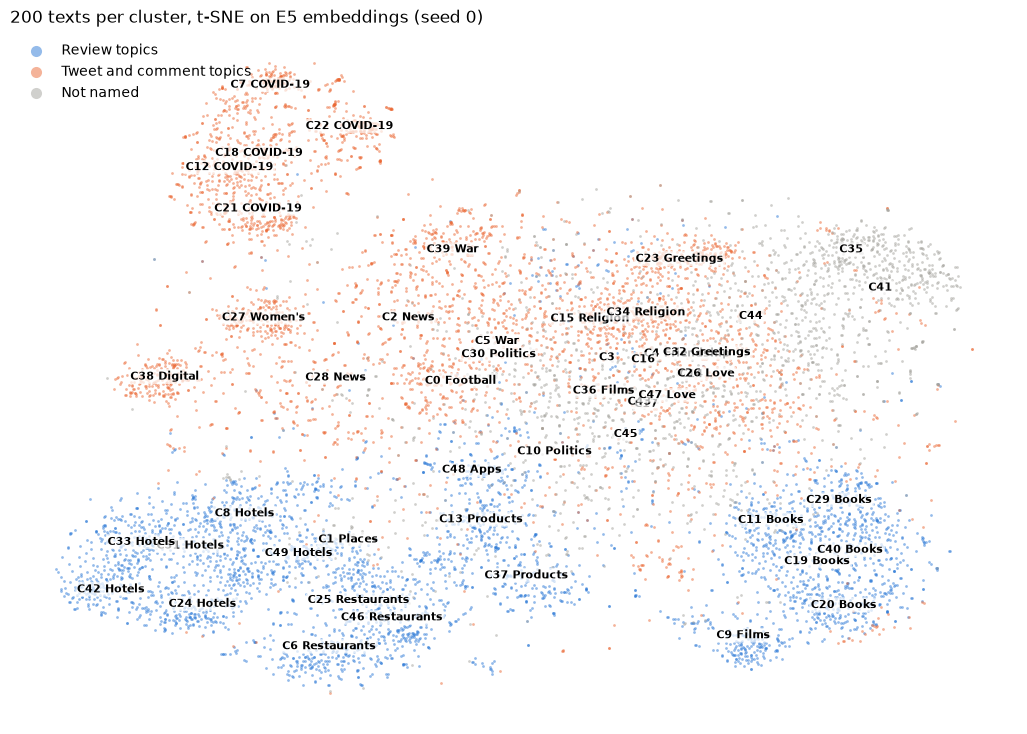

In [3]:
pts = L["points"]
xs, ys, cs = np.array([p["x"] for p in pts]), np.array([p["y"] for p in pts]), np.array([p["c"] for p in pts])
fig, ax = plt.subplots(figsize=(13, 9))
for g, label in [("review", "Review topics"), ("tweet", "Tweet and comment topics"), ("unnamed", "Not named")]:
    m = np.array([group(c) == g for c in cs])
    ax.scatter(xs[m], ys[m], s=4, alpha=0.5, color=COLORS[g], label=label, linewidths=0)
for c in sorted(set(cs)):
    m = cs == c
    name = "" if CL[c]["topic"] == "Not named" else " " + CL[c]["topic"].split()[0].rstrip(",")
    ax.text(xs[m].mean(), ys[m].mean(), f"C{c}{name}", fontsize=8, fontweight="bold", ha="center",
            bbox={"boxstyle": "round,pad=0.15", "fc": "white", "ec": "none", "alpha": 0.7})
ax.set_xticks([]); ax.set_yticks([])
ax.spines[:].set_visible(False)
ax.legend(loc="upper left", frameon=False, markerscale=4)
ax.set_title(f"{L['per_cluster']} texts per cluster, t-SNE on E5 embeddings (seed {L['seed']})", loc="left")
plt.show()

## Centroid similarity, ordered by the cluster tree

Cosine similarity between the 50 cluster centres (darker = closer), rows and columns in the order of the average-linkage tree drawn on top. White dots = two clusters with the same name.

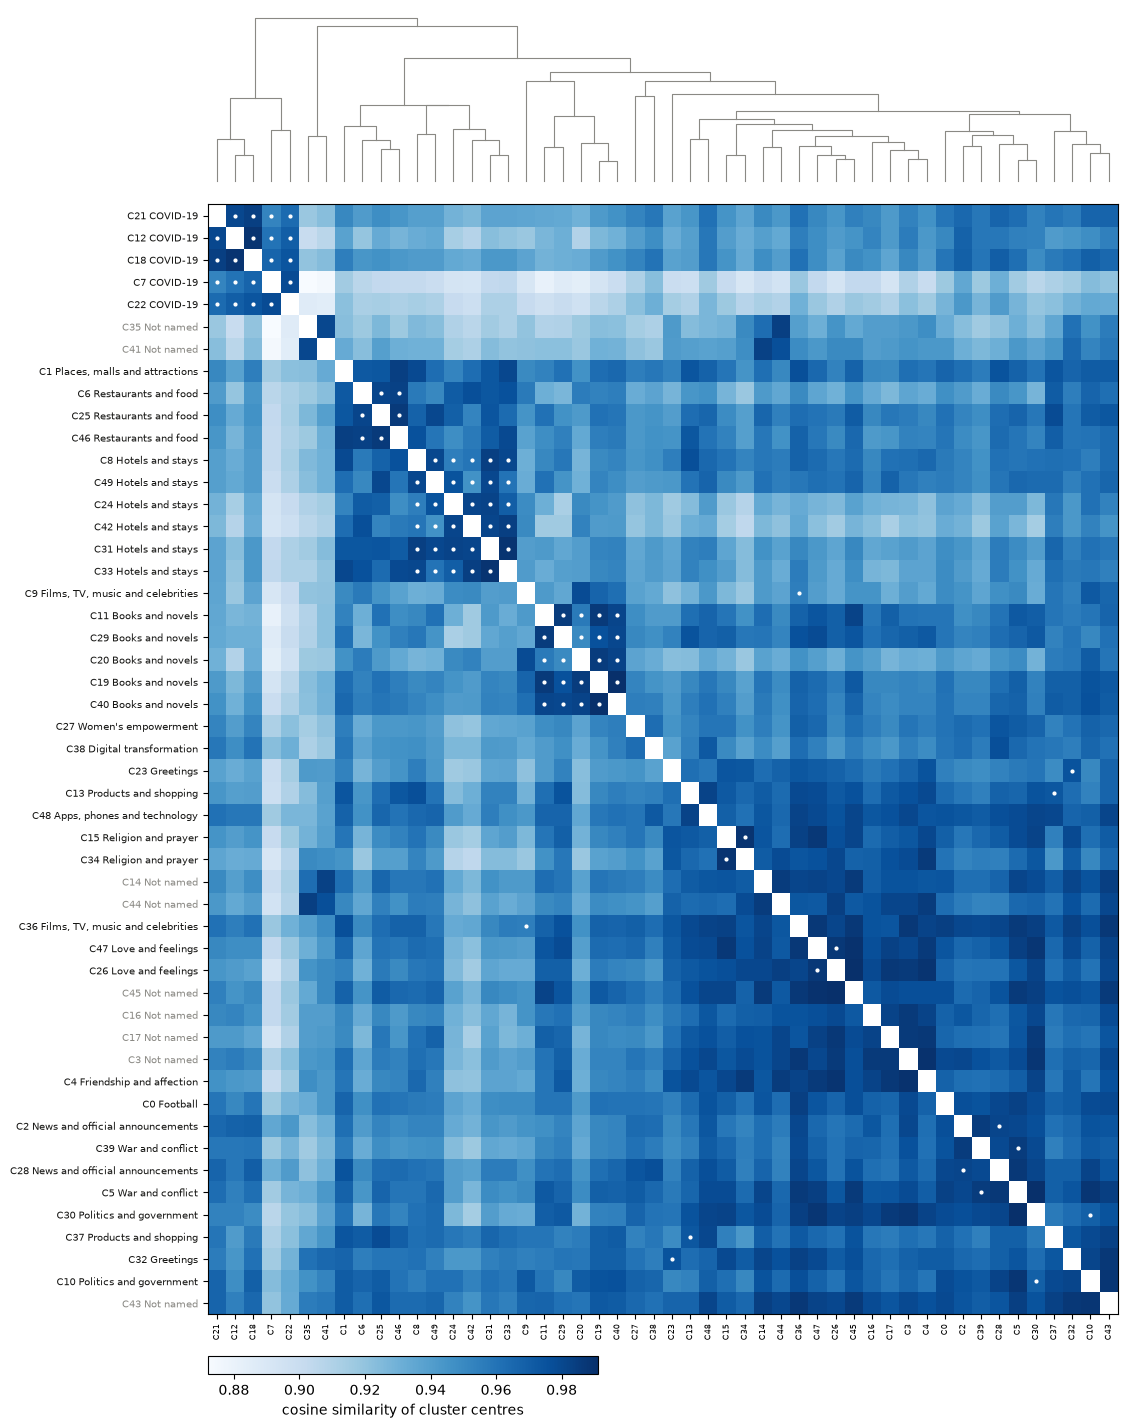

In [4]:
order = A["order"]
S = np.array(A["similarity"])[np.ix_(order, order)]
off = S[~np.eye(len(order), dtype=bool)]
S_plot = S.copy()
np.fill_diagonal(S_plot, np.nan)

fig = plt.figure(figsize=(13, 15))
ax_tree = fig.add_axes([0.25, 0.83, 0.70, 0.12])
ax_heat = fig.add_axes([0.25, 0.08, 0.70, 0.74])
ax_bar = fig.add_axes([0.25, 0.04, 0.30, 0.012])

# Tree: scipy leaf positions are 5, 15, 25, ...; heights are 1 - cosine.
for ic, dc in zip(A["dendrogram"]["icoord"], A["dendrogram"]["dcoord"]):
    ax_tree.plot([(v - 5) / 10 for v in ic], dc, color="#8a8984", lw=0.8)
ax_tree.set_xlim(-0.5, len(order) - 0.5)
ax_tree.axis("off")

im = ax_heat.imshow(S_plot, cmap="Blues", vmin=off.min(), vmax=off.max(), aspect="auto", interpolation="nearest")
for i, ci in enumerate(order):
    for j, cj in enumerate(order):
        if i != j and CL[ci]["topic"] == CL[cj]["topic"] != "Not named":
            ax_heat.plot(j, i, "o", color="white", ms=2)
labels = [f"C{c} {CL[c]['topic']}" for c in order]
ax_heat.set_yticks(range(len(order)), labels, fontsize=7)
ax_heat.set_xticks(range(len(order)), [f"C{c}" for c in order], fontsize=6, rotation=90)
for t, c in zip(ax_heat.get_yticklabels(), order):
    t.set_color("#8a8984" if CL[c]["topic"] == "Not named" else "#151513")
fig.colorbar(im, cax=ax_bar, orientation="horizontal", label="cosine similarity of cluster centres")
plt.show()

## Unnamed clusters: nearest named topics

*Closer to named* = share of the cluster's texts whose best named centre is closer than their own centre. *Texts would go to* = where its texts land if each is moved to the nearest named centre.

In [5]:
print(f"{'cluster':8s} {'what it is':38s} {'texts':>6s}  {'own sim':>7s} {'best named':>10s} {'closer to named':>15s}  texts would go to")
for c, u in A["unnamed"].items():
    go = ", ".join(f"{t} {s:.0%}" for t, s in list(u["texts_to_topic"].items())[:3])
    print(f"C{c:7s} {u['why']:38s} {u['size']:6,d}  {u['mean_sim_own']:7.3f} {u['mean_sim_best_named']:10.3f} "
          f"{u['share_closer_to_named_than_own']:15.1%}  {go}")
print()
for c, u in A["unnamed"].items():
    near = "; ".join(f"C{n['cluster']} {n['topic']} ({n['sim']:.3f})" for n in u["nearest_named"])
    print(f"C{c}: nearest named centres {near}")

cluster  what it is                              texts  own sim best named closer to named  texts would go to
C14      mixed Egyptian and Gulf chatter         5,361    0.927      0.919            0.1%  Love and feelings 29%, Greetings 17%, Politics and government 12%
C45      mixed personal chatter                  4,440    0.930      0.926            0.2%  Love and feelings 49%, Films, TV, music and celebrities 10%, War and conflict 8%
C3       short mixed tweets                      4,848    0.915      0.911            0.8%  Friendship and affection 36%, Politics and government 18%, Films, TV, music and celebrities 15%
C43      mixed Maghrebi and Gulf chatter         4,739    0.919      0.914            0.4%  Politics and government 23%, Greetings 22%, Films, TV, music and celebrities 16%
C44      very short emoji replies                4,579    0.927      0.917            0.2%  Friendship and affection 43%, Love and feelings 31%, Greetings 9%
C35      very short emoji replies       